# Experiment 2: Synthetic Generalized Mixed-Variable Optimization

Evaluation of the **Generalized $(\mu, \lambda)$-Evolution Strategy** with synthetic benchmark functions combining all 6 variable types:
- **Real ($\mathbb{R}$)**: Continuous variables with Gaussian perturbation and log-normal self-adaptation $\sigma_{\text{real}}$
- **Count ($\mathbb{Z}$)**: Integer counts with Skellam mutation (Poisson difference) and log-normal self-adaptation $\lambda_{\text{count}}$
- **Binary ($\mathbb{B}$)**: Logit-mapped activation probabilities and logit-normal self-adaptation $\text{logit}_{\text{binary}}$
- **Categorical ($\mathbb{C}$)**: Softmax sampling over logit vectors and logit-normal self-adaptation $\text{logit}_{\text{cat}}$
- **Fuzzy ($\mathbb{F}$)**: Triangular control points $(a, b, c)$ with unit reflection, interlocking monotonicity ($a \le b \le c$), and log-normal self-adaptation $\sigma_{\text{fuzzy}}$
- **Circular ($\mathbb{S}^1$)**: Modular Skellam mutation on discrete ring ($\bmod k$) with log-normal self-adaptation $\lambda_{\text{circular}}$

In [2]:
from pathlib import Path
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is in sys.path
cwd = Path.cwd().resolve()
project_root = None
for parent in [cwd] + list(cwd.parents):
    if (parent / "src").is_dir():
        project_root = parent
        break
if project_root is None:
    project_root = cwd.parent if (cwd.parent / "src").is_dir() else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.es_model.config import ESConfig
from src.es_model.individual import Individual, unpack_genome
from src.es_model.generalized_es import GeneralizedES
from src.runners.custom_es import run as run_generalized_es
from src.benchmarks.generalized_functions import (
    GENERALIZED_BENCHMARKS,
    generalized_sphere,
    generalized_rastrigin,
    generalized_coupled,
)


## 1. Experiment Execution Configuration

The experiment can be toggled between **Phase 1 (Smoke Test)** and **Phase 2 (Production Run)**:

In [3]:
# Set SMOKE_RUN = True for quick validation (Phase 1), False for production results (Phase 2)
SMOKE_RUN = False

if SMOKE_RUN:
    MAX_EVALS = 1000
    N_SEEDS = 2
    print(">>> PHASE 1: Smoke Validation Mode (1,000 evaluations, 2 seeds)")
else:
    MAX_EVALS = 20000
    N_SEEDS = 10
    print(">>> PHASE 2: Production Run Mode (20,000 evaluations, 10 seeds)")

# Generalized genome configuration testing all 6 variable types
CONFIG = ESConfig(
    mu=15,
    lam=100,
    n_real=5,
    n_count=3,
    n_binary=4,
    n_categorical=2,
    categorical_k=np.array([3, 4], dtype=np.int64),
    n_fuzzy=2,
    n_circular=2,
    circular_k=np.array([7, 12], dtype=np.int64),
    seed=42,
)

print(f"\nGeneralized ES Hyperparameters:")
print(f"  Survivors (mu): {CONFIG.mu}, Offspring (lambda): {CONFIG.lam}")
print(f"  Active Dimensions: Real={CONFIG.n_real}, Count={CONFIG.n_count}, Binary={CONFIG.n_binary}, Categorical={CONFIG.n_categorical}, Fuzzy={CONFIG.n_fuzzy} (x3 pts), Circular={CONFIG.n_circular}")
print(f"  Total Active Genome Dimensionality (n_total): {CONFIG.n_total}")


>>> PHASE 2: Production Run Mode (20,000 evaluations, 10 seeds)

Generalized ES Hyperparameters:
  Survivors (mu): 15, Offspring (lambda): 100
  Active Dimensions: Real=5, Count=3, Binary=4, Categorical=2, Fuzzy=2 (x3 pts), Circular=2
  Total Active Genome Dimensionality (n_total): 22


## 2. Multi-Seed Optimization Execution

Executes the Generalized ES on all 3 synthetic benchmarks with random seeds:

In [4]:
results = {}
SEEDS = [42 + i * 101 for i in range(N_SEEDS)] # Pseudo-random seeds

for bench_name, bench_info in GENERALIZED_BENCHMARKS.items():
    print(f"\n==========================================")
    print(f" Running Benchmark: {bench_name}")
    print(f" {bench_info['description']}")
    print(f"==========================================")
    
    fn = bench_info["fn"]
    eval_fn = lambda ind_or_x, _fn=fn: _fn(ind_or_x, config=CONFIG)
    
    seed_traces = []
    for idx, seed in enumerate(SEEDS):
        trace = run_generalized_es(
            fn=eval_fn,
            dim=CONFIG.n_real,
            bounds=(CONFIG.lower_bound_real, CONFIG.upper_bound_real),
            seed=seed,
            max_evals=MAX_EVALS,
            config=CONFIG,
        )
        seed_traces.append(trace)
        if (idx + 1) % max(1, N_SEEDS // 5) == 0 or idx == N_SEEDS - 1:
            print(f"  Seed {seed:5d} ({idx+1:2d}/{N_SEEDS}) | Final Best Fitness: {trace[-1]:.6e}")
            
    traces_arr = np.array(seed_traces)
    results[bench_name] = {
        "mean": np.mean(traces_arr, axis=0),
        "std": np.std(traces_arr, axis=0),
        "min": np.min(traces_arr, axis=0),
        "max": np.max(traces_arr, axis=0),
        "traces": traces_arr,
    }

# --- Save Convergence Traces to experiments/data/experiment_2/ ---
data_dir = os.path.join(project_root, "experiments", "data", "experiment_2")
os.makedirs(data_dir, exist_ok=True)

save_dict = {
    f"{bench_name}__traces": res["traces"]
    for bench_name, res in results.items()
}
save_dict["seeds"] = np.array(SEEDS, dtype=np.int64)

traces_path = os.path.join(data_dir, "exp2_traces.npz")
np.savez_compressed(traces_path, **save_dict)
print(f"\nSuccessfully saved experiment 2 traces to: {traces_path}")



 Running Benchmark: Generalized_Sphere
 Convex separable mixed-variable benchmark across all 6 variable types
  Seed   143 ( 2/10) | Final Best Fitness: 6.380917e-07
  Seed   345 ( 4/10) | Final Best Fitness: 2.886918e-07
  Seed   547 ( 6/10) | Final Best Fitness: 1.530838e-07
  Seed   749 ( 8/10) | Final Best Fitness: 5.898650e-07
  Seed   951 (10/10) | Final Best Fitness: 2.953344e-08

 Running Benchmark: Generalized_Rastrigin
 Multi-modal non-convex mixed-variable benchmark with cosine oscillations
  Seed   143 ( 2/10) | Final Best Fitness: 1.990151e+00
  Seed   345 ( 4/10) | Final Best Fitness: 9.952820e-01
  Seed   547 ( 6/10) | Final Best Fitness: 1.992101e+00
  Seed   749 ( 8/10) | Final Best Fitness: 9.950787e-01
  Seed   951 (10/10) | Final Best Fitness: 1.926816e-05

 Running Benchmark: Generalized_Coupled
 Coupled mixed-variable benchmark with discrete regime switches
  Seed   143 ( 2/10) | Final Best Fitness: 1.365662e-08
  Seed   345 ( 4/10) | Final Best Fitness: 1.382662

## 3. Convergence Curves (Fitness vs. Evaluations)

Plots the mean fitness convergence curve with $\pm 1$ standard deviation across all random seeds:

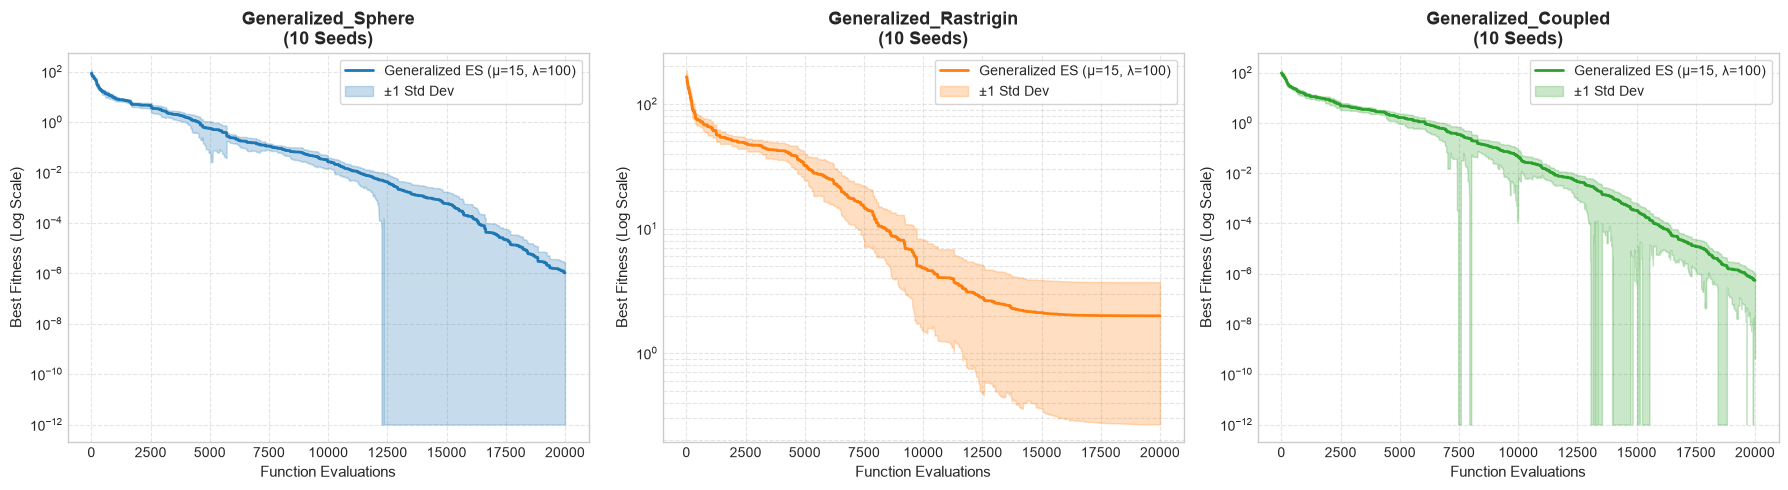

In [5]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

bench_names = list(GENERALIZED_BENCHMARKS.keys())
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for i, bench_name in enumerate(bench_names):
    ax = axes[i]
    res = results[bench_name]
    evals = np.arange(1, MAX_EVALS + 1)
    
    mean_trace = res["mean"]
    std_trace = res["std"]
    
    ax.plot(evals, mean_trace, color=colors[i], lw=2.0, label=f"Generalized ES (μ={CONFIG.mu}, λ={CONFIG.lam})")
    ax.fill_between(evals, np.maximum(1e-12, mean_trace - std_trace), mean_trace + std_trace, color=colors[i], alpha=0.25, label="±1 Std Dev")
    
    ax.set_title(f"{bench_name}\n({N_SEEDS} Seeds)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Function Evaluations", fontsize=11)
    ax.set_ylabel("Best Fitness (Log Scale)", fontsize=11)
    ax.set_yscale("log")
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
# plt.savefig("experiment_2_convergence.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Heterogeneous Variable & Strategy Dynamics (Multi-Seed Analysis)

Comprehensive 3-panel diagnostic tracking of all 6 decision variable types across all benchmark functions (Mean $\pm 1$ Std across all random seeds):
- **Panel A (Mutation Intensities & Step Sizes)**: Log-scale evolution of continuous and discrete step rates ($\sigma_{\text{real}}, \lambda_{\text{count}}, \sigma_{\text{fuzzy}}, \lambda_{\text{circular}}$).
- **Panel B (Probabilities & Information Certainty)**: Bounded $[0, 1]$ metrics tracking binary flip probability $p_{\text{flip}} = \sigma(\text{logit}_{\text{binary}})$, categorical maximum confidence $\max(p)$, and normalized Shannon entropy $H(p)/\ln(K)$ demonstrating uncertainty collapse.
- **Panel C (Fitness Error Decomposition)**: Log-scale partial fitness contributions ($f_{\text{real}}, f_{\text{count}}, f_{\text{binary}}, f_{\text{cat}}, f_{\text{fuzzy}}, f_{\text{circular}}$) revealing the exact sequence and generation of resolution for each variable type.

>>> Tracking Heterogeneous Dynamics: Generalized_Sphere (10 Seeds)


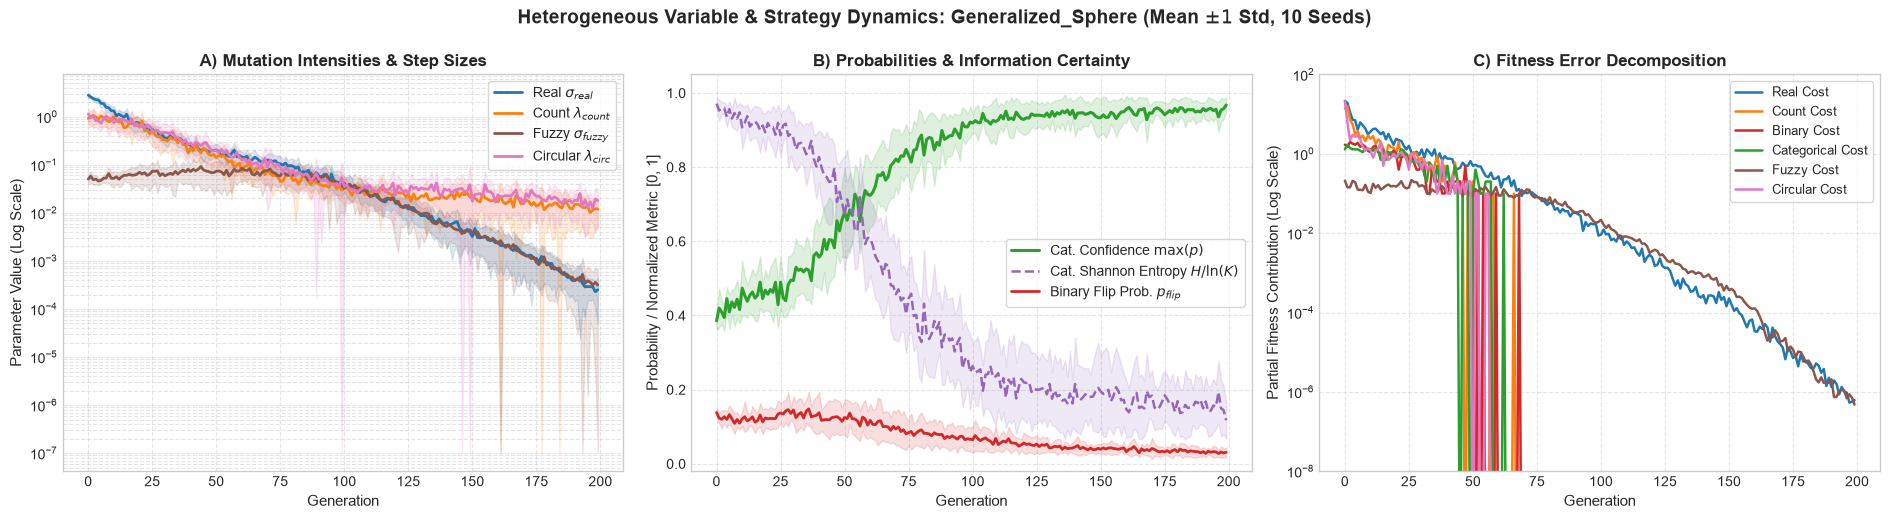

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_2\exp2_generalized_sphere_dynamics.png
>>> Tracking Heterogeneous Dynamics: Generalized_Rastrigin (10 Seeds)


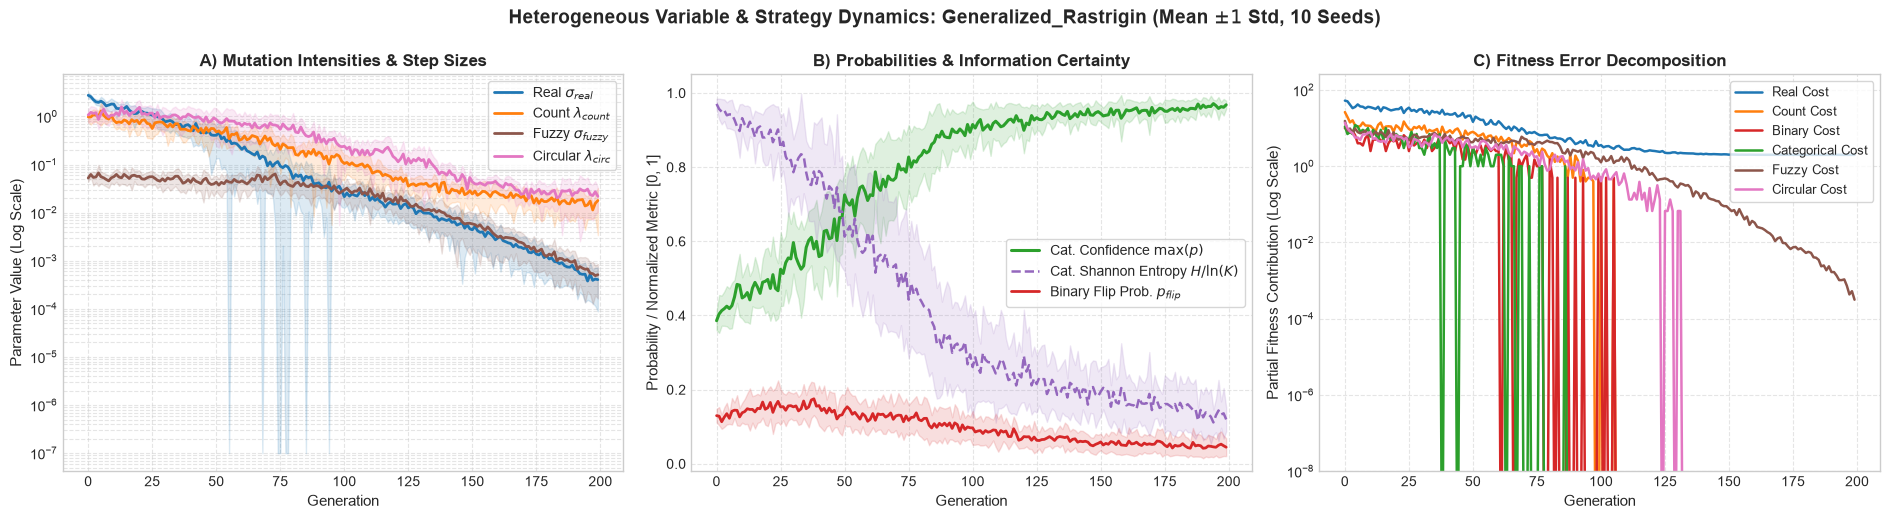

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_2\exp2_generalized_rastrigin_dynamics.png
>>> Tracking Heterogeneous Dynamics: Generalized_Coupled (10 Seeds)


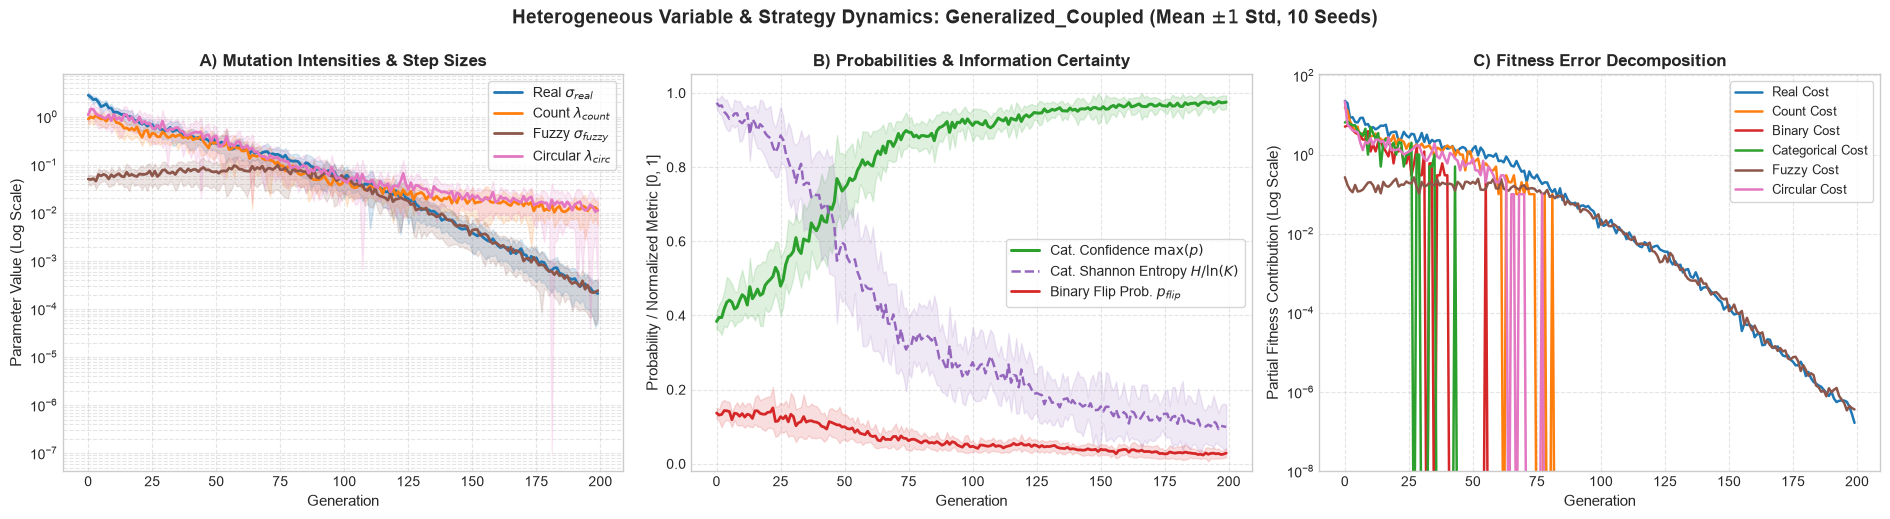

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_2\exp2_generalized_coupled_dynamics.png

Successfully saved complete heterogeneous dynamics to: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_2\exp2_strategy_dynamics.npz


In [6]:
from pathlib import Path
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is in sys.path even if executed standalone
cwd = Path.cwd().resolve()
for parent in [cwd] + list(cwd.parents):
    if (parent / "src").is_dir() and str(parent) not in sys.path:
        sys.path.insert(0, str(parent))
        break

from src.es_model.config import ESConfig
from src.es_model.individual import unpack_genome
from src.es_model.generalized_es import GeneralizedES
from src.benchmarks.generalized_functions import GENERALIZED_BENCHMARKS, get_default_targets

# Fallback defaults if executed standalone without running preceding cells
if "CONFIG" not in globals():
    CONFIG = ESConfig(
        mu=15,
        lam=100,
        n_real=5,
        n_count=3,
        n_binary=4,
        n_categorical=2,
        categorical_k=np.array([3, 4], dtype=np.int64),
        n_fuzzy=2,
        n_circular=2,
        circular_k=np.array([7, 12], dtype=np.int64),
        seed=42,
    )

if "MAX_EVALS" not in globals():
    MAX_EVALS = 20000
if "N_SEEDS" not in globals():
    N_SEEDS = 10
if "SEEDS" not in globals():
    SEEDS = [42 + i * 101 for i in range(N_SEEDS)]

if "data_dir" not in globals():
    roots = [p for p in [cwd] + list(cwd.parents) if (p / "src").is_dir()]
    root = roots[0] if roots else cwd.parent
    data_dir = os.path.join(str(root), "experiments", "data", "experiment_2")
os.makedirs(data_dir, exist_ok=True)

n_generations = MAX_EVALS // CONFIG.lam

def compute_decomposition(ind, bench_name, cfg):
    t = get_default_targets(cfg)
    u = unpack_genome(ind, cfg)
    if bench_name == "Generalized_Sphere":
        c_real = float(np.sum((u.real - t["real"]) ** 2)) if cfg.n_real > 0 else 0.0
        c_count = float(np.sum((u.count - t["count"]) ** 2)) if cfg.n_count > 0 else 0.0
        c_bin = float(np.sum(u.binary != t["binary"])) if cfg.n_binary > 0 else 0.0
        c_cat = float(np.sum(u.categorical != t["categorical"])) if cfg.n_categorical > 0 else 0.0
        c_fuzz = float(np.sum((u.fuzzy - t["fuzzy"]) ** 2)) if cfg.n_fuzzy > 0 else 0.0
        k = t["circular_k"]
        diff = np.abs(u.circular - t["circular"]) % k
        c_circ = float(np.sum(np.minimum(diff, k - diff) ** 2)) if cfg.n_circular > 0 else 0.0
    elif bench_name == "Generalized_Rastrigin":
        diff_r = u.real - t["real"]
        c_real = float(10.0 * cfg.n_real + np.sum(diff_r ** 2 - 10.0 * np.cos(2.0 * np.pi * diff_r))) if cfg.n_real > 0 else 0.0
        diff_c = (u.count - t["count"]).astype(np.float64)
        c_count = float(2.0 * cfg.n_count + np.sum(diff_c ** 2 - 2.0 * np.cos(np.pi * diff_c))) if cfg.n_count > 0 else 0.0
        c_bin = float(5.0 * np.sum(u.binary != t["binary"])) if cfg.n_binary > 0 else 0.0
        c_cat = float(10.0 * np.sum(u.categorical != t["categorical"])) if cfg.n_categorical > 0 else 0.0
        diff_f = u.fuzzy - t["fuzzy"]
        n_pts = cfg.n_fuzzy * 3
        c_fuzz = float(5.0 * n_pts + np.sum(diff_f ** 2 - 5.0 * np.cos(2.0 * np.pi * diff_f))) if cfg.n_fuzzy > 0 else 0.0
        k = t["circular_k"]
        phase = 2.0 * np.pi * (u.circular - t["circular"]) / k
        c_circ = float(5.0 * np.sum(1.0 - np.cos(phase))) if cfg.n_circular > 0 else 0.0
    elif bench_name == "Generalized_Coupled":
        regime_offset = float(u.categorical[0]) if cfg.n_categorical > 0 else 0.0
        target_real_shifted = t["real"] + regime_offset * 0.5
        c_bin = float(np.sum(u.binary != 1)) * 3.0 if cfg.n_binary > 0 else 0.0
        count_scale = float(1.0 + 0.1 * np.abs(u.count[0] - t["count"][0])) if cfg.n_count > 0 else 1.0
        c_real = float(np.sum((u.real - target_real_shifted) ** 2)) if cfg.n_real > 0 else 0.0
        c_cat = float(5.0 * np.sum(u.categorical != 0)) if cfg.n_categorical > 0 else 0.0
        c_count = float(np.sum((u.count - t["count"]) ** 2)) if cfg.n_count > 0 else 0.0
        c_fuzz = float(count_scale * np.sum((u.fuzzy - t["fuzzy"]) ** 2)) if cfg.n_fuzzy > 0 else 0.0
        k = t["circular_k"]
        diff = np.abs(u.circular - t["circular"]) % k
        c_circ = float(np.sum(np.minimum(diff, k - diff) ** 2)) if cfg.n_circular > 0 else 0.0
    else:
        raise ValueError(f"Unknown benchmark: {bench_name}")
    return {
        "cost_real": c_real,
        "cost_count": c_count,
        "cost_binary": c_bin,
        "cost_cat": c_cat,
        "cost_fuzzy": c_fuzz,
        "cost_circular": c_circ,
    }

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
all_saved_data = {}

for bench_name, bench_info in GENERALIZED_BENCHMARKS.items():
    print(f">>> Tracking Heterogeneous Dynamics: {bench_name} ({N_SEEDS} Seeds)")
    fn = bench_info["fn"]
    eval_fn = lambda ind_or_x, _fn=fn: _fn(ind_or_x, config=CONFIG)
    seed_data = []
    for seed in SEEDS:
        es = GeneralizedES(config=CONFIG, seed=seed)
        es.init_population(eval_fn)
        history = {
            "sigma_real": [],
            "lambda_count": [],
            "sigma_fuzzy": [],
            "lambda_circular": [],
            "p_flip_binary": [],
            "cat_confidence": [],
            "cat_entropy_norm": [],
            "cost_real": [],
            "cost_count": [],
            "cost_binary": [],
            "cost_cat": [],
            "cost_fuzzy": [],
            "cost_circular": [],
        }
        for g in range(n_generations):
            es.step(eval_fn)
            best_p = es.parents[0]
            history["sigma_real"].append(np.mean(best_p.sigma_real))
            history["lambda_count"].append(np.mean(best_p.lambda_count))
            history["sigma_fuzzy"].append(np.mean(best_p.sigma_fuzzy))
            history["lambda_circular"].append(np.mean(best_p.lambda_circular))
            p_flips = 1.0 / (1.0 + np.exp(-np.clip(best_p.logit_binary, -700.0, 700.0)))
            history["p_flip_binary"].append(np.mean(p_flips))
            offset = 0
            confs = []
            entropies = []
            for k in CONFIG.categorical_k:
                k_int = int(k)
                sl = best_p.logit_cat[offset : offset + k_int]
                ez = np.exp(sl - np.max(sl))
                probs = ez / np.sum(ez)
                confs.append(np.max(probs))
                h = -np.sum(probs * np.log(np.maximum(probs, 1e-12))) / np.log(k_int)
                entropies.append(h)
                offset += k_int
            history["cat_confidence"].append(np.mean(confs))
            history["cat_entropy_norm"].append(np.mean(entropies))
            decomp = compute_decomposition(best_p, bench_name, CONFIG)
            for k_cost, v_cost in decomp.items():
                history[k_cost].append(v_cost)
        seed_data.append({k: np.array(v) for k, v in history.items()})

    bench_agg = {}
    for m in seed_data[0].keys():
        stacked = np.array([sd[m] for sd in seed_data])
        bench_agg[f"{m}_mean"] = np.mean(stacked, axis=0)
        bench_agg[f"{m}_std"] = np.std(stacked, axis=0)
        all_saved_data[f"{bench_name}__{m}_mean"] = bench_agg[f"{m}_mean"]
        all_saved_data[f"{bench_name}__{m}_std"] = bench_agg[f"{m}_std"]
        all_saved_data[f"{bench_name}__{m}_raw"] = stacked

    # --- 3-Panel Visual Diagnostics ---
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
    gens = np.arange(n_generations)

    # Panel A: Mutation Step Sizes & Rates (Log scale)
    ax1 = axes[0]
    m_keys_1 = [
        ("sigma_real", r"Real $\sigma_{real}$", "#1f77b4", "-"),
        ("lambda_count", r"Count $\lambda_{count}$", "#ff7f0e", "-"),
        ("sigma_fuzzy", r"Fuzzy $\sigma_{fuzzy}$", "#8c564b", "-"),
        ("lambda_circular", r"Circular $\lambda_{circ}$", "#e377c2", "-"),
    ]
    for key, lbl, col, ls in m_keys_1:
        mean_v = bench_agg[f"{key}_mean"]
        std_v = bench_agg[f"{key}_std"]
        ax1.plot(gens, mean_v, label=lbl, color=col, ls=ls, lw=2.0)
        ax1.fill_between(gens, np.maximum(mean_v - std_v, 1e-7), mean_v + std_v, color=col, alpha=0.15)
    ax1.set_title("A) Mutation Intensities & Step Sizes", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Generation", fontsize=11)
    ax1.set_ylabel("Parameter Value (Log Scale)", fontsize=11)
    ax1.set_yscale("log")
    ax1.grid(True, which="both", ls="--", alpha=0.5)
    ax1.legend(loc="upper right", frameon=True, fontsize=10)

    # Panel B: Probabilities & Certainty [0, 1]
    ax2 = axes[1]
    m_keys_2 = [
        ("cat_confidence", r"Cat. Confidence $\max(p)$", "#2ca02c", "-", 2.2),
        ("cat_entropy_norm", r"Cat. Shannon Entropy $H/\ln(K)$", "#9467bd", "--", 1.8),
        ("p_flip_binary", r"Binary Flip Prob. $p_{flip}$", "#d62728", "-", 2.0),
    ]
    for key, lbl, col, ls, lw in m_keys_2:
        mean_v = bench_agg[f"{key}_mean"]
        std_v = bench_agg[f"{key}_std"]
        ax2.plot(gens, mean_v, label=lbl, color=col, ls=ls, lw=lw)
        ax2.fill_between(gens, np.clip(mean_v - std_v, 0.0, 1.0), np.clip(mean_v + std_v, 0.0, 1.0), color=col, alpha=0.15)
    ax2.set_title("B) Probabilities & Information Certainty", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Generation", fontsize=11)
    ax2.set_ylabel("Probability / Normalized Metric [0, 1]", fontsize=11)
    ax2.set_ylim(-0.02, 1.05)
    ax2.grid(True, which="both", ls="--", alpha=0.5)
    ax2.legend(loc="center right", frameon=True, fontsize=10)

    # Panel C: Fitness Error Decomposition per Variable Type
    ax3 = axes[2]
    m_keys_3 = [
        ("cost_real", "Real Cost", "#1f77b4"),
        ("cost_count", "Count Cost", "#ff7f0e"),
        ("cost_binary", "Binary Cost", "#d62728"),
        ("cost_cat", "Categorical Cost", "#2ca02c"),
        ("cost_fuzzy", "Fuzzy Cost", "#8c564b"),
        ("cost_circular", "Circular Cost", "#e377c2"),
    ]
    for key, lbl, col in m_keys_3:
        mean_v = np.maximum(bench_agg[f"{key}_mean"], 1e-12)
        ax3.plot(gens, mean_v, label=lbl, color=col, lw=1.8)
    ax3.set_title("C) Fitness Error Decomposition", fontsize=12, fontweight="bold")
    ax3.set_xlabel("Generation", fontsize=11)
    ax3.set_ylabel("Partial Fitness Contribution (Log Scale)", fontsize=11)
    ax3.set_yscale("log")
    ax3.set_ylim(bottom=1e-8)
    ax3.grid(True, which="both", ls="--", alpha=0.5)
    ax3.legend(loc="upper right", frameon=True, fontsize=9.5)

    fig.suptitle(f"Heterogeneous Variable & Strategy Dynamics: {bench_name} (Mean $\\pm 1$ Std, {N_SEEDS} Seeds)", fontsize=14, fontweight="bold", y=0.99)
    plt.tight_layout()
    fig_path = os.path.join(data_dir, f"exp2_{bench_name.lower()}_dynamics.png")
    plt.savefig(fig_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {fig_path}")

# --- Save Aggregated Strategy & Variable Dynamics ---
all_saved_data["generations"] = np.arange(n_generations)
all_saved_data["seeds"] = np.array(SEEDS)
dynamics_path = os.path.join(data_dir, "exp2_strategy_dynamics.npz")
np.savez_compressed(dynamics_path, **all_saved_data)
print(f"\nSuccessfully saved complete heterogeneous dynamics to: {dynamics_path}")


## 5. Statistical Results Summary Table

In [7]:
print("==========================================================================================")
print(f" EXPERIMENT 2 RESULTS SUMMARY ({N_SEEDS} Seeds | {MAX_EVALS} Max Evaluations)")
print("==========================================================================================")
print(f"{'Benchmark Function':<25} | {'Mean Best Fitness':<20} | {'Std Dev':<18} | {'Min (Best Run)':<18}")
print("-" * 88)

for bench_name, res in results.items():
    final_mean = res["mean"][-1]
    final_std = res["std"][-1]
    final_min = res["min"][-1]
    print(f"{bench_name:<25} | {final_mean:<20.6e} | {final_std:<18.6e} | {final_min:<18.6e}")

print("==========================================================================================")


 EXPERIMENT 2 RESULTS SUMMARY (10 Seeds | 20000 Max Evaluations)
Benchmark Function        | Mean Best Fitness    | Std Dev            | Min (Best Run)    
----------------------------------------------------------------------------------------
Generalized_Sphere        | 1.048018e-06         | 1.648035e-06       | 2.953344e-08      
Generalized_Rastrigin     | 1.990463e+00         | 1.723436e+00       | 1.926816e-05      
Generalized_Coupled       | 5.437395e-07         | 5.433162e-07       | 1.365662e-08      
